# Twitter Sentiment Analysis
OIBSIP – Level 1, Task 4 
## Project objective
Build a model that classifies airline-related tweets as **positive, neutral, or negative**.

This notebook uses the `Tweets.csv` file from the Twitter Airline Sentiment dataset. It includes explanations before each major coding step.

### Before you start
1. Download and extract the dataset ZIP file.
2. Place `Tweets.csv` in the `data` folder beside this notebook.
3. If your file has a different name or location, update `DATA_PATH` in the next cell.
4. Run the notebook from top to bottom.

**Target column:** `airline_sentiment`  
**Text column:** `text`


## 1. Import libraries
We use:
- **Pandas / NumPy** to work with data.
- **Matplotlib / Seaborn** for charts.
- **Scikit-learn** for splitting data, TF-IDF, machine-learning models, and evaluation.
- **Regular expressions** to remove links and unwanted text patterns.

If a library is missing, install it from Anaconda Prompt or a notebook cell using `%pip install package-name`.


In [16]:
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Change this path if your CSV is stored somewhere else.
DATA_PATH = "Tweets.csv"


## 2. Load the dataset
`pd.read_csv()` reads the CSV file into a DataFrame.

If you get `FileNotFoundError`, check the spelling of the file and its folder. For example, if `Tweets.csv` is beside the notebook, use `DATA_PATH = "Tweets.csv"`.


In [17]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())


Dataset shape: (14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)



Column names:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


## 3. Inspect the dataset
First, check data types, missing values, and duplicate rows. This helps us understand the dataset before changing it.

The expected dataset contains columns such as `text` and `airline_sentiment`. If these columns are absent, inspect the column list above and update the column names in the configuration cell below.


In [18]:
display(df.info())
print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nDuplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created                 14640 non-null  object 
 13  t

None


Missing values:


negativereason_gold             14608
airline_sentiment_gold          14600
tweet_coord                     13621
negativereason                   5462
user_timezone                    4820
tweet_location                   4733
negativereason_confidence        4118
tweet_id                            0
airline_sentiment                   0
airline_sentiment_confidence        0
airline                             0
name                                0
retweet_count                       0
text                                0
tweet_created                       0
dtype: int64


Duplicate rows: 36


## 4. Select the text and target columns
The model learns from tweet text (`text`) and predicts its sentiment (`airline_sentiment`).

We keep only these two columns for the main classification task. Rows with missing text or labels are removed.


In [19]:
TEXT_COL = "text"
TARGET_COL = "airline_sentiment"

if TEXT_COL not in df.columns or TARGET_COL not in df.columns:
    raise KeyError(
        f"Expected columns '{TEXT_COL}' and '{TARGET_COL}'. "
        f"Available columns: {df.columns.tolist()}"
    )

data = df[[TEXT_COL, TARGET_COL]].copy()
data = data.dropna(subset=[TEXT_COL, TARGET_COL])
data[TEXT_COL] = data[TEXT_COL].astype(str)
data[TARGET_COL] = data[TARGET_COL].astype(str).str.strip().str.lower()
data = data.drop_duplicates()

print("Cleaned shape:", data.shape)
print("\nSentiment labels:")
print(data[TARGET_COL].value_counts())


Cleaned shape: (14452, 2)

Sentiment labels:
airline_sentiment
negative    9087
neutral     3067
positive    2298
Name: count, dtype: int64


## 5. Explore sentiment distribution
This bar chart shows how many positive, neutral, and negative tweets are present.

If one class has many more examples than another, the dataset is imbalanced. This matters because accuracy alone may hide weak performance on a smaller class.


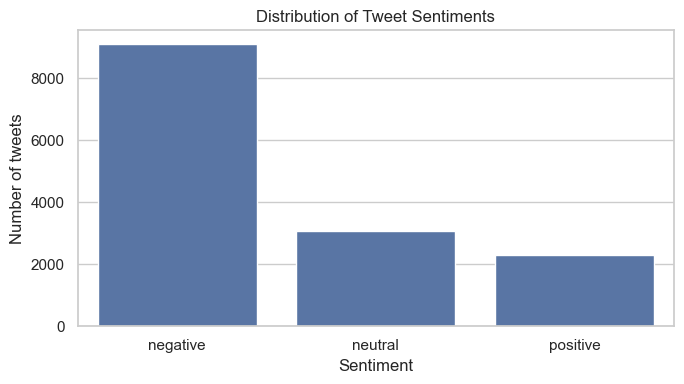

airline_sentiment
negative    62.88
neutral     21.22
positive    15.90
Name: Percentage, dtype: float64

In [20]:
plt.figure(figsize=(7, 4))
order = data[TARGET_COL].value_counts().index
sns.countplot(data=data, x=TARGET_COL, order=order)
plt.title("Distribution of Tweet Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of tweets")
plt.tight_layout()
plt.show()

display(data[TARGET_COL].value_counts(normalize=True).mul(100).round(2).rename("Percentage"))


## 6. Clean the tweet text
Tweets may contain URLs, usernames, HTML fragments, repeated spaces, and punctuation noise.

The function below:
1. Converts text to lowercase.
2. Removes web links and `@user` mentions.
3. Removes the `#` symbol but keeps the hashtag word.
4. Removes HTML fragments and extra whitespace.



In [21]:
def clean_tweet(text):
    text = str(text).lower()
    text = re.sub(r"http\\S+|www\\.\\S+", " ", text)  # URLs
    text = re.sub(r"@\\w+", " ", text)                 # usernames
    text = re.sub(r"<.*?>", " ", text)                   # HTML tags
    text = text.replace("#", " ")                        # keep hashtag word
    text = re.sub(r"[^a-z0-9'\\s]", " ", text)          # punctuation/symbols
    text = re.sub(r"\\s+", " ", text).strip()           # extra spaces
    return text

data["clean_text"] = data[TEXT_COL].apply(clean_tweet)

display(data[[TEXT_COL, "clean_text", TARGET_COL]].head(10))


,text,clean_text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,virginamerica what dhepburn said,neutral
1,@VirginAmerica plus you've added commercials t...,virginamerica plus you've added commercials to...,positive
2,@VirginAmerica I didn't today... Must mean I n...,virginamerica i didn't today must mean i ne...,neutral
3,@VirginAmerica it's really aggressive to blast...,virginamerica it's really aggressive to blast ...,negative
4,@VirginAmerica and it's a really big bad thing...,virginamerica and it's a really big bad thing ...,negative
5,@VirginAmerica seriously would pay $30 a fligh...,virginamerica seriously would pay 30 a flight...,negative
6,"@VirginAmerica yes, nearly every time I fly VX...",virginamerica yes nearly every time i fly vx ...,positive
7,@VirginAmerica Really missed a prime opportuni...,virginamerica really missed a prime opportunit...,neutral
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",virginamerica well i didn't but now i do d,positive
9,"@VirginAmerica it was amazing, and arrived an ...",virginamerica it was amazing and arrived an h...,positive


## 7. Prepare features and labels
- **X** contains the cleaned tweet text.
- **y** contains the sentiment label to predict.

We use a stratified train-test split. `stratify=y` keeps approximately the same class proportions in both sets. The test set is held back for final evaluation.


In [22]:
X = data["clean_text"]
y = data[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("\nTraining label distribution:")
print(y_train.value_counts(normalize=True).round(3))


Training examples: 11561
Testing examples: 2891

Training label distribution:
airline_sentiment
negative    0.629
neutral     0.212
positive    0.159
Name: proportion, dtype: float64


## 8. TF-IDF vectorisation
Machine-learning models cannot directly understand raw text. **TF-IDF** converts words into numerical features.

- Words frequent in a particular tweet can receive higher importance.
- Words that occur in almost every tweet are given less distinguishing weight.
- `ngram_range=(1, 2)` considers both single words and two-word phrases.

The vectoriser is placed inside a Pipeline so it is fitted only on training data. This prevents information from the test set leaking into training.


In [23]:
tfidf_options = dict(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)


## 9. Train Logistic Regression
Logistic Regression is a strong baseline for text classification. It learns which word patterns are associated with each sentiment class.

The pipeline performs TF-IDF conversion and model training together.


In [24]:
logistic_model = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_options)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression accuracy:",
      round(accuracy_score(y_test, logistic_predictions), 4))
print("\nClassification report:")
print(classification_report(y_test, logistic_predictions, zero_division=0))


Logistic Regression accuracy: 0.7804

Classification report:
              precision    recall  f1-score   support

    negative       0.89      0.83      0.86      1818
     neutral       0.57      0.66      0.61       613
    positive       0.70      0.74      0.72       460

    accuracy                           0.78      2891
   macro avg       0.72      0.74      0.73      2891
weighted avg       0.79      0.78      0.79      2891



## 10. Train Multinomial Naive Bayes
Multinomial Naive Bayes is another common baseline for text classification. It estimates class probabilities using word-feature counts/weights.

We train it with the same TF-IDF settings and the same train/test split so the comparison is fair.


In [25]:
naive_bayes_model = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_options)),
    ("classifier", MultinomialNB())
])

naive_bayes_model.fit(X_train, y_train)
nb_predictions = naive_bayes_model.predict(X_test)

print("Naive Bayes accuracy:",
      round(accuracy_score(y_test, nb_predictions), 4))
print("\nClassification report:")
print(classification_report(y_test, nb_predictions, zero_division=0))


Naive Bayes accuracy: 0.7043

Classification report:
              precision    recall  f1-score   support

    negative       0.69      1.00      0.81      1818
     neutral       0.84      0.18      0.30       613
    positive       0.90      0.24      0.38       460

    accuracy                           0.70      2891
   macro avg       0.81      0.47      0.50      2891
weighted avg       0.76      0.70      0.64      2891



## 11. Compare the models
Accuracy is the proportion of all predictions that are correct. Macro F1 gives equal importance to each class, making it useful when class counts differ.

Choose the model based on the evaluation results, not on assumptions about which algorithm is better.


,Model,Accuracy,Macro F1
0,Logistic Regression,0.7804,0.73
1,Multinomial Naive Bayes,0.7043,0.50


<Figure size 800x400 with 0 Axes>

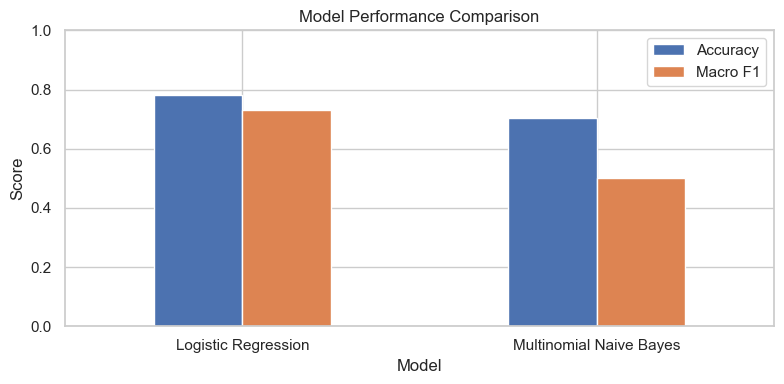

In [26]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Multinomial Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, nb_predictions)
    ],
    "Macro F1": [
        __import__("sklearn.metrics").metrics.f1_score(
            y_test, logistic_predictions, average="macro"
        ),
        __import__("sklearn.metrics").metrics.f1_score(
            y_test, nb_predictions, average="macro"
        )
    ]
}).sort_values("Macro F1", ascending=False)

display(results.round(4))

plt.figure(figsize=(8, 4))
results.set_index("Model")[["Accuracy", "Macro F1"]].plot(
    kind="bar", figsize=(8, 4), ylim=(0, 1), rot=0
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.tight_layout()
plt.show()


## 12. Confusion matrix for the selected model
A confusion matrix compares actual labels with predicted labels. Correct predictions appear along the diagonal. Off-diagonal values show which sentiments are being confused.

The code selects the model with the higher macro F1 score from the comparison above.


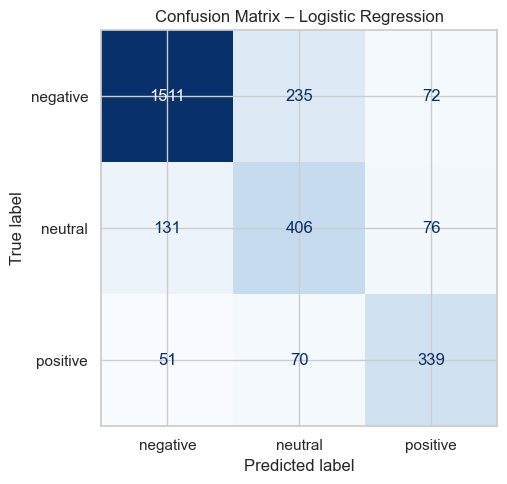

Selected model: Logistic Regression
              precision    recall  f1-score   support

    negative       0.89      0.83      0.86      1818
     neutral       0.57      0.66      0.61       613
    positive       0.70      0.74      0.72       460

    accuracy                           0.78      2891
   macro avg       0.72      0.74      0.73      2891
weighted avg       0.79      0.78      0.79      2891



In [27]:
from sklearn.metrics import f1_score

if f1_score(y_test, logistic_predictions, average="macro") >= f1_score(
    y_test, nb_predictions, average="macro"
):
    best_model = logistic_model
    best_predictions = logistic_predictions
    best_model_name = "Logistic Regression"
else:
    best_model = naive_bayes_model
    best_predictions = nb_predictions
    best_model_name = "Multinomial Naive Bayes"

labels = sorted(y.unique())
cm = confusion_matrix(y_test, best_predictions, labels=labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
plt.title(f"Confusion Matrix – {best_model_name}")
plt.tight_layout()
plt.show()

print("Selected model:", best_model_name)
print(classification_report(y_test, best_predictions, zero_division=0))


## 13. Test the model with your own tweets
Use this function to predict the sentiment of a new sentence. The model returns one of the sentiment classes learned from the training data.

Remember: this dataset is specifically about airline-related tweets, so predictions on unrelated topics may be less reliable.


In [28]:
def predict_sentiment(tweet):
    prediction = best_model.predict([clean_tweet(tweet)])[0]
    return prediction

examples = [
    "The flight was amazing and the staff were very helpful!",
    "My flight was delayed for five hours. Terrible service.",
    "My flight from Delhi to Mumbai is scheduled for tomorrow."
]

for sentence in examples:
    print("Tweet:", sentence)
    print("Predicted sentiment:", predict_sentiment(sentence))
    print("-" * 70)


Tweet: The flight was amazing and the staff were very helpful!
Predicted sentiment: positive
----------------------------------------------------------------------
Tweet: My flight was delayed for five hours. Terrible service.
Predicted sentiment: negative
----------------------------------------------------------------------
Tweet: My flight from Delhi to Mumbai is scheduled for tomorrow.
Predicted sentiment: neutral
----------------------------------------------------------------------


## 14. Save the trained model (optional)
This saves the complete pipeline, including TF-IDF and the classifier. You can load it later without retraining.

Only save the model after the notebook has successfully trained and evaluated it.


In [29]:
import joblib

MODEL_PATH = "sentiment_model.joblib"
joblib.dump(best_model, MODEL_PATH)
print(f"Model saved to: {MODEL_PATH}")


Model saved to: sentiment_model.joblib


## 15. Project conclusion
Complete this section after running the notebook. Use the actual results printed above; do not invent or copy example scores.

Include:
- Number of rows used after cleaning.
- Sentiment class distribution.
- Best-performing model.
- Test accuracy and macro F1 score.
- Which sentiment classes were easiest or hardest to predict, based on the classification report and confusion matrix.
- Limitations: airline-specific data, informal language, sarcasm, spelling variation, and possible class imbalance.

### Final checklist
- [ ] Correct CSV loaded.
- [ ] Missing values and duplicates checked.
- [ ] Text cleaned.
- [ ] Train/test split created with stratification.
- [ ] TF-IDF and both models trained.
- [ ] Metrics and confusion matrix reviewed.
- [ ] Own example tweets tested.
- [ ] README updated with actual results.
- [ ] Notebook saved and committed to GitHub.
